In [ ]:
!pip install -q pandas matplotlib openpyxl numpy


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

In [ ]:
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

In [ ]:
E_MIN, E_MAX = 1.0, 20.0

In [ ]:
FILES = {
    "EXFOR": "Fe-54_n_p_Mn-54_exfor.csv",                              # experimental
    "TENDL": "Fe54__tendl.csv",                                        # TENDL-2023
    "ENDF":  "Fe_54___n_p___cross_section_data_jendl_200_MeV_endf.txt",# evaluated (eV/barn)
    "JEFF":  "JEFF_Fe54_np_CrossSection_1MeV_to_40MeV.csv",            # JEFF
    "TALYS": "TALYS_DATA_for_Fe_54__csv.xlsx",                         # TALYS predictions
}

In [ ]:
ALIASES = {
    "EXFOR": ["EXFOR_Fe54_np.txt", "EXFOR_Fe54_np.csv"],
    "TENDL": ["TENDL_Fe54_np.csv"],
    "ENDF":  ["ENDF_Fe54_np.txt"],
    "JEFF":  ["JEFF_Fe54_np.csv"],
    "TALYS": ["TALYS_Fe54_np.xlsx"],
}

def resolve(key):
    """Return the first existing path for a given library, else None."""
    for cand in [FILES[key]] + ALIASES.get(key, []):
        if cand and os.path.exists(cand):
            return cand
    return None

B_TO_MB = 1000.0   # barns -> millibarns
EV_TO_MEV = 1e-6   # eV    -> MeV


In [ ]:
def parse_exfor(path):
    """EXFOR experimental CSV: energy_MeV, cross_section_b, uncertainties,
    author, year. Returns a tidy DataFrame in MeV / mb."""
    df = pd.read_csv(path)
    out = pd.DataFrame({
        "energy_MeV":  pd.to_numeric(df["energy_MeV"], errors="coerce"),
        "xs_mb":       pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB,
        "dE_MeV":      pd.to_numeric(df.get("d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":      pd.to_numeric(df.get("d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":      df.get("author", "Unknown").astype(str).str.strip(),
        "year":        pd.to_numeric(df.get("year", 0), errors="coerce").fillna(0).astype(int),
    })
    out = out.dropna(subset=["energy_MeV", "xs_mb"])
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0]
    # human-readable "Author (Year)" label used for color-coding
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out.reset_index(drop=True)


def parse_tendl(path):
    """TENDL CSV (TALYS YANDF export). Data already in MeV / mb;
    a long '#'-comment header precedes 'E,xs'."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(',').strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if s.lower().startswith("e,") or s.lower() == "e,xs":
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                e  = float(parts[0])
                xs = float(parts[1])
            except ValueError:
                continue
            rows.append((e, xs))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])  # already MeV, mb
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_endf(path):
    """ENDF / JENDL point file: 'E[eV]  Sig[b]  Interpolation'.
    Lines beginning with '#' are header. Convert eV->MeV, b->mb."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()
            if len(parts) < 2:
                continue
            try:
                e_ev  = float(parts[0])
                sig_b = float(parts[1])
            except ValueError:
                continue
            rows.append((e_ev * EV_TO_MEV, sig_b * B_TO_MB))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_jeff(path):
    """JEFF CSV with columns Energy_eV, CrossSection_barns, Energy_MeV."""
    df = pd.read_csv(path)
    if "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    out = pd.DataFrame({"energy_MeV": e, "xs_mb": xs}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)


def parse_talys(path):
    """TALYS xlsx: paired (Energy[MeV], sigma[mb]) blocks for several
    level-density models. Uses ldmodel1 as the primary TALYS curve."""
    raw = pd.read_excel(path, header=None)
    # Row 0 holds model titles like 'Fe 54 (ldmodel1)'; row 1 holds the
    # 'Energy [MeV] / sigma [mb]' sub-headers; numeric data start at row 2.
    titles = raw.iloc[0].tolist()
    # locate the column index where 'ldmodel1' lives
    start_col = 0
    for i, t in enumerate(titles):
        if isinstance(t, str) and "ldmodel1" in t.replace(" ", "").lower():
            start_col = i
            break
    e  = pd.to_numeric(raw.iloc[2:, start_col],     errors="coerce")
    xs = pd.to_numeric(raw.iloc[2:, start_col + 1], errors="coerce")
    out = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)


In [ ]:
PARSERS = {
    "EXFOR": parse_exfor,
    "TENDL": parse_tendl,
    "ENDF":  parse_endf,
    "JEFF":  parse_jeff,
    "TALYS": parse_talys,
}

data = {}
for key, parser in PARSERS.items():
    path = resolve(key)
    if path is None:
        print(f"[WARNING] {key}: file not found "
              f"(looked for '{FILES[key]}' and aliases) — skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        print(f"[OK] {key:5s}: {len(data[key]):4d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None


[WARNING] EXFOR: file not found (looked for 'Fe-54_n_p_Mn-54_exfor.csv' and aliases) — skipping.
[WARNING] TENDL: file not found (looked for 'Fe54__tendl.csv' and aliases) — skipping.
[WARNING] ENDF: file not found (looked for 'Fe_54___n_p___cross_section_data_jendl_200_MeV_endf.txt' and aliases) — skipping.
[WARNING] JEFF: file not found (looked for 'JEFF_Fe54_np_CrossSection_1MeV_to_40MeV.csv' and aliases) — skipping.
[WARNING] TALYS: file not found (looked for 'TALYS_DATA_for_Fe_54__csv.xlsx' and aliases) — skipping.


/tmp/ipykernel_3011/2621024513.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right", fontsize=10, ncol=2,


Saved plot -> Fe54_np_combined_comparison_plot.png


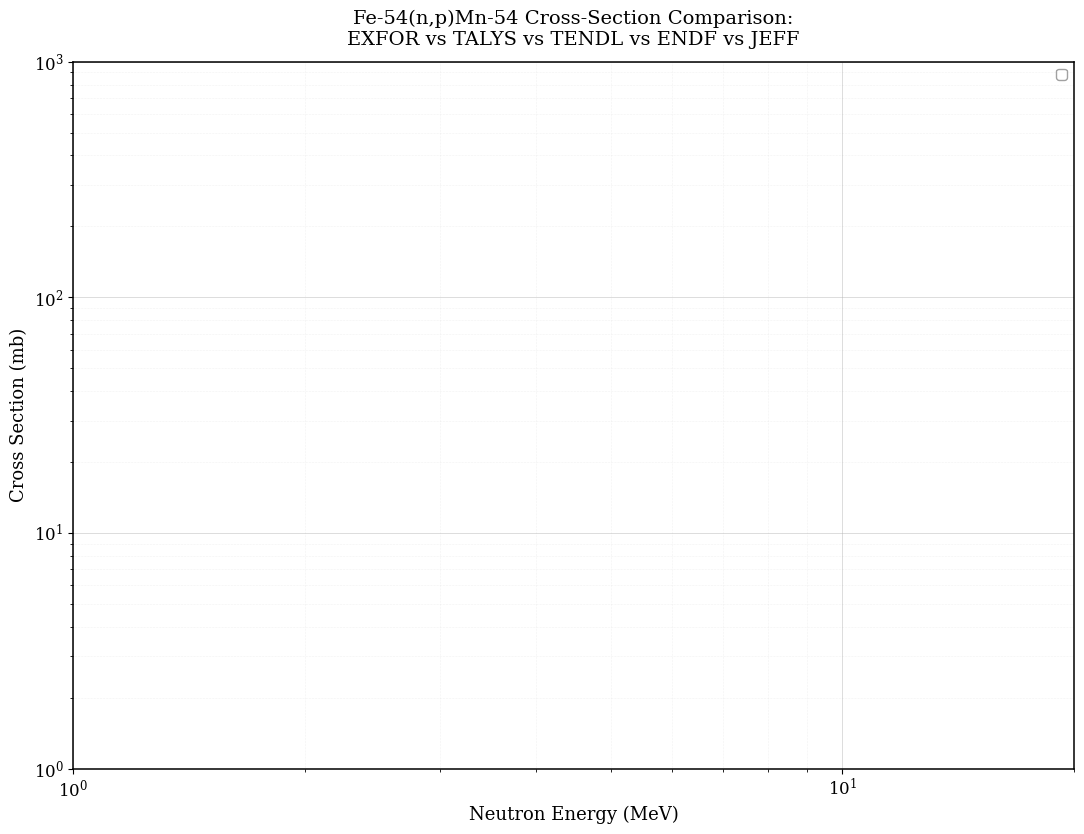

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8.5))

# ---- theoretical / evaluated curves -----------------------------------------
#  distinct line styles + colors per the reference image
CURVE_STYLE = {
    "TALYS": dict(color="#3a0f6e", ls="-",  lw=2.4, label="TALYS"),
    "TENDL": dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF":  dict(color="#e8702a", ls="-.", lw=2.2, label="ENDF/B (JENDL)"),
    "JEFF":  dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TALYS", "TENDL", "ENDF", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

# ---- EXFOR experimental points, color-coded by author/year ------------------
exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    # rank authors by point count; show top N individually, rest as "Other"
    TOP_N = 10
    counts = exfor["label"].value_counts()
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor.copy()
    exfor["plot_label"] = np.where(exfor["label"].isin(top_labels),
                                   exfor["label"], "Other measurements")

    plot_labels = top_labels + (["Other measurements"]
                                if (exfor["plot_label"] == "Other measurements").any()
                                else [])
    cmap = plt.cm.tab20(np.linspace(0, 1, max(len(plot_labels), 1)))
    markers = ["o", "s", "^", "v", "D", "<", ">", "p", "*", "h", "X", "P"]

    for i, lab in enumerate(plot_labels):
        sub = exfor[exfor["plot_label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt=markers[i % len(markers)],
            color=cmap[i], ecolor=cmap[i],
            markersize=5, capsize=3, elinewidth=0.9, capthick=0.9,
            linestyle="none", alpha=0.85, label=lab, zorder=2,
        )

# ---- log-log axes, range, ticks, grid ---------------------------------------
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(E_MIN, E_MAX)            # 1–20 MeV display window (all sources present)
ax.set_ylim(1, 1000)                 # 1–1000 mb (peak ~550 mb in this window)

ax.set_xlabel("Neutron Energy (MeV)", fontsize=13)
ax.set_ylabel("Cross Section (mb)", fontsize=13)
ax.set_title(
    "Fe-54(n,p)Mn-54 Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs ENDF vs JEFF",
    fontsize=14, pad=12,
)

ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.xaxis.set_minor_formatter(NullFormatter())

ax.grid(which="major", ls="-",  lw=0.6, alpha=0.5)
ax.grid(which="minor", ls=":",  lw=0.4, alpha=0.3)

# ---- legend in upper-right (two columns to avoid covering data) -------------
ax.legend(loc="upper right", fontsize=10, ncol=2,
          framealpha=0.92, edgecolor="0.6")

fig.tight_layout()

OUT_PNG = "Fe54_np_combined_comparison_plot.png"
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
print(f"Saved plot -> {OUT_PNG}")

In [ ]:
frames = []
for key, df in data.items():
    if df is None or not len(df):
        continue
    tmp = df.copy()
    tmp["source"] = key
    if key == "EXFOR":
        tmp = tmp[["source", "energy_MeV", "xs_mb", "dE_MeV", "dxs_mb",
                   "author", "year"]]
    else:
        tmp = tmp[["source", "energy_MeV", "xs_mb"]]
        tmp["dE_MeV"] = np.nan
        tmp["dxs_mb"] = np.nan
        tmp["author"] = np.nan
        tmp["year"]   = np.nan
    frames.append(tmp)

combined = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
combined = combined.sort_values(["source", "energy_MeV"]).reset_index(drop=True)

OUT_CSV = "Fe54_np_parsed_data.csv"
combined.to_csv(OUT_CSV, index=False)
print(f"Saved data -> {OUT_CSV}  ({len(combined)} rows)")

# ---- summary statistics file ------------------------------------------------
OUT_TXT = "Fe54_np_summary_statistics.txt"
with open(OUT_TXT, "w") as f:
    f.write("Fe-54(n,p)Mn-54 Cross-Section Data — Summary Statistics\n")
    f.write("=" * 60 + "\n")
    f.write(f"Comparison energy window: {E_MIN}-{E_MAX} MeV\n\n")
    for key, df in data.items():
        f.write(f"[{key}]\n")
        if df is None or not len(df):
            f.write("  (no data / file missing)\n\n")
            continue
        f.write(f"  points        : {len(df)}\n")
        f.write(f"  energy range  : {df['energy_MeV'].min():.4g} - "
                f"{df['energy_MeV'].max():.4g} MeV\n")
        f.write(f"  xs min        : {df['xs_mb'].min():.4g} mb\n")
        f.write(f"  xs max        : {df['xs_mb'].max():.4g} mb\n")
        if key == "EXFOR":
            f.write(f"  unique authors: {df['author'].nunique()}\n")
            f.write(f"  year range    : {int(df['year'].min())}-"
                    f"{int(df['year'].max())}\n")
        f.write("\n")
print(f"Saved stats -> {OUT_TXT}")
print("\n".join(open(OUT_TXT).read().splitlines()))


KeyError: 'source'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')